--- DATA PREVIEW ---
   cgpa   iq  placement
0  6.69   95          0
1  9.28  123          1
2  8.29  115          1
3  7.69   91          0
4  5.70   81          0

Dataset Shape: (100, 3)
Placed: 42 | Not Placed: 58


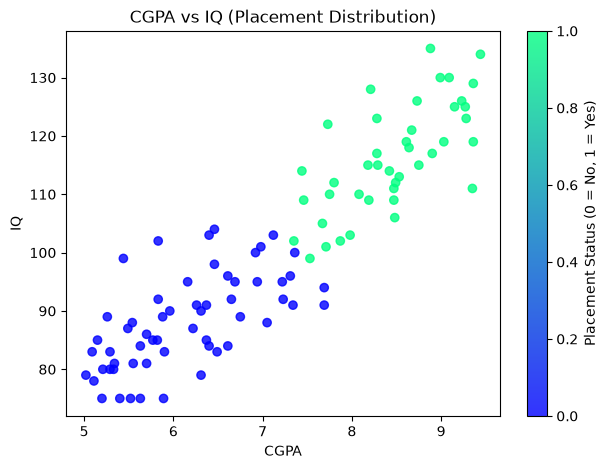

Saved scatter plot as 'placement_scatter.png'

Training samples: 90
Test samples:     10

Model Accuracy on Test Set: 100.00%


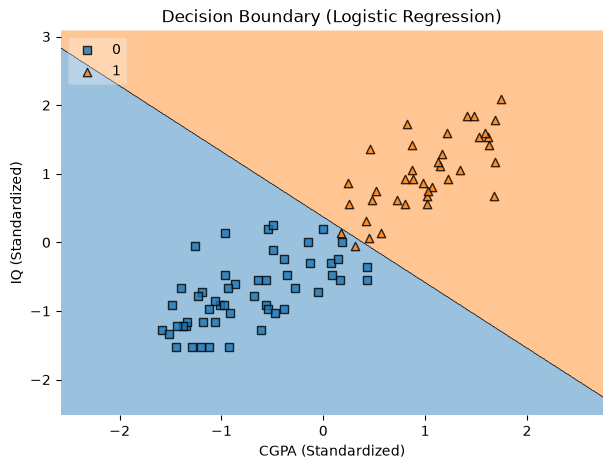

Saved decision boundary plot as 'decision_boundary.png'

Successfully serialized and saved 'model.pkl' and 'scaler.pkl'!


In [2]:
import pickle
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ===========================================================
# 1. GENERATE & SAVE PLACEMENT DATASET LOCALLY
# ===========================================================
np.random.seed(42)

# Generate 100 realistic samples
cgpa = np.random.uniform(5.0, 9.5, 100).round(2)
iq = (cgpa * 12 + np.random.normal(loc=15, scale=8, size=100)).astype(int)
iq = np.clip(iq, 75, 135)

# Calculate placement binary target (0 = Not Placed, 1 = Placed)
score_metric = 0.5 * (cgpa - 5.0) / 4.5 + 0.5 * (iq - 75) / 60
placement = (score_metric > 0.48).astype(int)

df = pd.DataFrame({'cgpa': cgpa, 'iq': iq, 'placement': placement})

# Save locally to ensure complete offline reproducibility
df.to_csv('placement.csv', index=False)

print('--- DATA PREVIEW ---')
print(df.head())
print(f'\nDataset Shape: {df.shape}')
print(f'Placed: {sum(df["placement"] == 1)} | Not Placed: {sum(df["placement"] == 0)}')

# ===========================================================
# 2. EXPLORATORY DATA ANALYSIS (EDA) & SCATTER PLOT
# ===========================================================
plt.figure(figsize=(7, 5))
plt.scatter(df['cgpa'], df['iq'], c=df['placement'], cmap='winter', alpha=0.8)
plt.title('CGPA vs IQ (Placement Distribution)')
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.colorbar(label='Placement Status (0 = No, 1 = Yes)')
plt.savefig('placement_scatter.png')
plt.show()
print("Saved scatter plot as 'placement_scatter.png'")

# ===========================================================
# 3. FEATURE-TARGET SPLIT & TRAIN-TEST PARTITION
# ===========================================================
X = df[['cgpa', 'iq']]
y = df['placement']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

print(f'\nTraining samples: {X_train.shape[0]}')
print(f'Test samples:     {X_test.shape[0]}')

# ===========================================================
# 4. FEATURE SCALING (AVOIDING DATA LEAKAGE)
# ===========================================================
scaler = StandardScaler()

# Fit on training data ONLY, then transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ===========================================================
# 5. MODEL TRAINING (LOGISTIC REGRESSION)
# ===========================================================
clf = LogisticRegression()
clf.fit(X_train_scaled, y_train)

# ===========================================================
# 6. EVALUATION
# ===========================================================
y_pred = clf.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f'\nModel Accuracy on Test Set: {accuracy * 100:.2f}%')

# ===========================================================
# 7. DECISION BOUNDARY VISUALIZATION (MLXTEND)
# ===========================================================
plt.figure(figsize=(7, 5))
plot_decision_regions(X_train_scaled, y_train.values, clf=clf, legend=2)
plt.title('Decision Boundary (Logistic Regression)')
plt.xlabel('CGPA (Standardized)')
plt.ylabel('IQ (Standardized)')
plt.savefig('decision_boundary.png')
plt.show()
print("Saved decision boundary plot as 'decision_boundary.png'")

# ===========================================================
# 8. ARTIFACT SERIALIZATION (EXPORTING FOR PRODUCTION)
# ===========================================================
pickle.dump(clf, open('model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))

print("\nSuccessfully serialized and saved 'model.pkl' and 'scaler.pkl'!")